# Toxic Comment Classification — COEP DSAI Club Induction 2026 (SY Task Round)

**Goal:** for every Wikipedia comment, predict six probabilities: `toxic`, `severe_toxic`, `obscene`, `threat`, `insult`, `identity_hate`.

## 1. Introduction



**Multi-label classification:** one comment can belong to several classes at once (e.g. both `toxic` *and* `insult`). This differs from multi-class classification, where each item has exactly one class. We handle it by training **one binary classifier per label** (One-vs-Rest).


**Metric:** the mean of the six per-label **ROC AUC** scores. ROC AUC measures how well the model *ranks* toxic comments above non-toxic ones, so we must output **probabilities**, not hard 0/1 predictions.



### 1.1 Candidate approaches (comparison before implementing)

These are *candidates*, not guaranteed rankings. Only the approaches marked "implemented" are validated below, all on the **same** validation split.

| Approach | Main idea | Advantages | Limitations | Computational cost | Suitability |
|---|---|---|---|---|---|
| TF-IDF + Logistic Regression | Word features with linear classifiers | Fast, interpretable, strong baseline | Limited contextual understanding | Low | Essential baseline (**implemented**) |
| Word + Character TF-IDF + Logistic Regression | Combine word and character n-grams | Captures phrases, misspellings, word variations | Larger feature matrix | Low to moderate | Strong candidate (**implemented**) |
| TF-IDF + Linear SVM | Linear SVM on text features | Often effective for sparse text | Scores need calibration to become probabilities | Low to moderate | Optional (not implemented) |
| TF-IDF + (Complement) Naive Bayes | Probabilistic model from word statistics | Fast and simple | Probability quality / ranking often worse | Low | Optional baseline (not implemented) |
| TF-IDF + SGDClassifier | Linear classifiers trained with stochastic gradient | Efficient on huge sparse data | Needs careful tuning; probabilities depend on loss | Low to moderate | Optional (not implemented) |
| Small neural net / shallow embedding model | Learn trainable text representations | Can model non-linear patterns | Harder to tune/explain; strict parameter budget | Moderate | Optional advanced (not implemented) |
| Small random-init text CNN | Learn local char/token patterns | Captures local patterns | More debugging; may underperform sparse linear models | Moderate | Optional advanced (not implemented) |
| Pretrained transformer / fine-tuned LM | Pretrained contextual representations | Strong language understanding | Pretrained weights exceed 1M parameters and use external knowledge | High | **Not allowed / not used** |

**Detail per approach**

| Approach | How text is represented | How six probabilities are produced | Parameter implications | Compliant? | Worth implementing in limited time? |
|---|---|---|---|---|---|
| Word TF-IDF + LR | Sparse vector of weighted word / bigram counts | 6 separate logistic regressions → sigmoid output each | `6 × (features + 1)` | Yes | Yes — baseline |
| Word + char TF-IDF + LR | Sparse vector of word **and** character n-gram weights | Same, with more input features | `6 × (features + 1)`, still < 1M if features ≤ ~100k | Yes | Yes — main improvement to test |
| Linear SVM | Same sparse vectors | Margin scores (need calibration for true probabilities; AUC only needs ranking) | Similar to LR | Yes | Optional; adds little over LR here |
| Naive Bayes | Word counts / TF-IDF | Class-conditional word statistics via Bayes' rule | ≈ classes × features | Yes | Optional; usually weaker ranking |
| SGDClassifier | Same sparse vectors | `loss="log_loss"` gives probabilities | Same as LR | Yes | Optional; mainly a speed tool |
| Small NN / embeddings | Dense learned word vectors | 6 sigmoid output units | Embedding table (`vocab × dim`) dominates the budget | Yes, if counted | Risky for a beginner; skipped |
| Text CNN | Learned embeddings + convolution filters | 6 sigmoid outputs | Embeddings + filters + dense layer | Yes, if counted | Skipped |
| Pretrained transformer | Contextual embeddings from external pretraining | 6 output units on top | Typically 10M–hundreds of millions of parameters | **No** (size + external knowledge) | No |

## 2. Imports and Dataset Loading



In [1]:
import os, glob, time, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
from IPython.display import display, Markdown

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")
SEED = 42                      # one seed used everywhere for reproducibility
np.random.seed(SEED)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
LABELS = ["toxic", "severe_toxic", "obscene", "threat", "insult", "identity_hate"]
PARAM_LIMIT = 1_000_000

In [2]:
# ---- Kaggle setup: input and output locations ----
# Attached inputs are mounted under /kaggle/input/. Anything saved to /kaggle/working/ appears in the notebook Output tab.
INPUT_ROOT = "/kaggle/input"   # change only if your data was attached somewhere else
OUT_DIR    = "/kaggle/working" # where submission.csv and README.md are written

def find_file(filename):
    # Search INPUT_ROOT recursively (we do not assume a dataset folder name); fail clearly if missing or ambiguous.
    hits = sorted(glob.glob(os.path.join(INPUT_ROOT, "**", filename), recursive=True))
    if not hits:
        raise FileNotFoundError(
            f"'{filename}' was not found under {INPUT_ROOT}. Attach the competition data with 'Add Input' "
            f"(and accept the competition rules), then re-run. Files found there: "
            f"{sorted(os.listdir(INPUT_ROOT)) if os.path.isdir(INPUT_ROOT) else 'directory does not exist'}")
    if len(hits) > 1:
        raise RuntimeError(f"Multiple files named '{filename}' found: {hits}. "
                           f"Set INPUT_ROOT above to the one folder you want to use.")
    return hits[0]

train_path = find_file("competition_train.csv")
test_path  = find_file("competition_test.csv")
sub_path   = find_file("sample_submission.csv")
print("train:", train_path); print("test :", test_path); print("sample submission:", sub_path)

train = pd.read_csv(train_path)
test  = pd.read_csv(test_path)
sample_sub = pd.read_csv(sub_path)

# Work out column names from the files instead of guessing.
ID_COL = sample_sub.columns[0]                     # first column of the submission = ID column
assert list(sample_sub.columns[1:]) == LABELS or set(sample_sub.columns[1:]) == set(LABELS), sample_sub.columns
SUB_COLUMNS = list(sample_sub.columns)             # exact required order
TEXT_COL = [c for c in train.columns if c not in LABELS + [ID_COL]][0]
print(f"\nID column = '{ID_COL}', text column = '{TEXT_COL}'")
print("Submission column order:", SUB_COLUMNS)

train: /kaggle/input/competitions/dsai-club-induction-2026-sy-task/competition_train.csv
test : /kaggle/input/competitions/dsai-club-induction-2026-sy-task/competition_test.csv
sample submission: /kaggle/input/competitions/dsai-club-induction-2026-sy-task/sample_submission.csv

ID column = 'id', text column = 'comment_text'
Submission column order: ['id', 'toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']


In [3]:
# Basic validation of the three files
assert ID_COL in train.columns and ID_COL in test.columns
assert TEXT_COL in test.columns, "test file has no text column"
assert all(l in train.columns for l in LABELS), "missing label columns in train"
assert train[LABELS].isin([0, 1]).all().all(), "labels must be binary 0/1"
assert train[ID_COL].is_unique and test[ID_COL].is_unique, "duplicate IDs found"
assert set(test[ID_COL]) == set(sample_sub[ID_COL]), "test IDs differ from sample submission IDs"

# Missing comments would crash the vectorizer; treat them as empty text (do not drop rows).
train[TEXT_COL] = train[TEXT_COL].fillna("").astype(str)
test[TEXT_COL]  = test[TEXT_COL].fillna("").astype(str)

print("Train shape:", train.shape, "| Test shape:", test.shape, "| Sample submission shape:", sample_sub.shape)
display(train.head(3)); display(test.head(3)); display(sample_sub.head(3))

Train shape: (127657, 8) | Test shape: (31914, 2) | Sample submission shape: (31914, 7)


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,dsai000000,"""The citation for the point """"It helped setup the recently formed Sufi Muslim Council"""" is not appropriate. The BBC ...",0,0,0,0,0,0
1,dsai000001,"What i'm talking about are edits such as this and this. Repeated undoing the good faith edits by other users, even i...",0,0,0,0,0,0
2,dsai000002,"March 2008 \n Please stop. If you continue to vandalize Wikipedia, you will be blocked from editing.",0,0,0,0,0,0


,id,comment_text
0,dsai127657,Right I have no reported you for breaking your revert parole. You have also acted in bad faith because you have thro...
1,dsai127658,How many Wikipedia editors does it take to screw in a lightbulb?
2,dsai127659,At the bottom there was only 1 paragraph from the entire poem/song. I don't believe this conveyed the message of the...


,id,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,dsai127657,0.5,0.5,0.5,0.5,0.5,0.5
1,dsai127658,0.5,0.5,0.5,0.5,0.5,0.5
2,dsai127659,0.5,0.5,0.5,0.5,0.5,0.5


## 3. Exploratory Data Analysis (EDA)

EDA means looking at the data *before* modelling so we know what we are dealing with: sizes, missing values, text length, and above all **how rare each label is**.

In [4]:
eda = pd.DataFrame({
    "Rows": [len(train), len(test)],
    "Columns": [train.shape[1], test.shape[1]],
    "Missing values (total)": [int(train.isna().sum().sum()), int(test.isna().sum().sum())],
    "Duplicate IDs": [int(train[ID_COL].duplicated().sum()), int(test[ID_COL].duplicated().sum())],
    "Empty comments": [int((train[TEXT_COL].str.strip() == "").sum()), int((test[TEXT_COL].str.strip() == "").sum())],
    "Exact duplicate comment texts": [int(train[TEXT_COL].duplicated().sum()), int(test[TEXT_COL].duplicated().sum())],
}, index=["train", "test"])
display(eda)

,Rows,Columns,Missing values (total),Duplicate IDs,Empty comments,Exact duplicate comment texts
train,127657,8,0,0,0,0
test,31914,2,0,0,0,0


,count,mean,std,min,25%,50%,75%,max
chars_train,127657.0,393.4,591.1,6.0,95.0,205.0,434.0,5000.0
words_train,127657.0,67.2,99.3,1.0,17.0,36.0,75.0,1411.0


Test comment length (chars):
 count    31914.0
mean       396.6
std        589.1
min         14.0
25%         97.0
50%        208.0
75%        441.0
max       5000.0


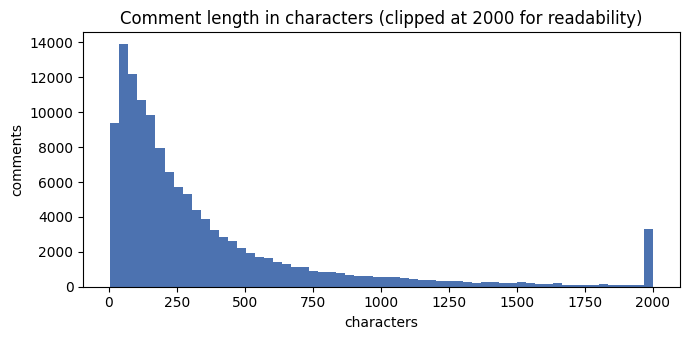

In [5]:
# Comment length statistics (characters and words)
lens = pd.DataFrame({
    "chars_train": train[TEXT_COL].str.len(), "words_train": train[TEXT_COL].str.split().str.len(),
})
display(lens.describe().T.round(1))
test_len = test[TEXT_COL].str.len().describe().round(1)
print("Test comment length (chars):\n", test_len.to_string())

fig, ax = plt.subplots(1, 1, figsize=(7, 3.5))
ax.hist(lens["chars_train"].clip(upper=2000), bins=60, color="#4C72B0")
ax.set_title("Comment length in characters (clipped at 2000 for readability)")
ax.set_xlabel("characters"); ax.set_ylabel("comments"); plt.tight_layout(); plt.show()

In [6]:
# Example comments with their labels (a few non-toxic, a few toxic).  NOTE: comments may contain offensive language.
display(Markdown("**Random non-toxic examples**"))
clean_mask = train[LABELS].sum(axis=1) == 0
display(train[clean_mask].sample(3, random_state=SEED)[[TEXT_COL] + LABELS])
display(Markdown("**Random toxic examples (offensive language ahead)**"))
display(train[~clean_mask].sample(3, random_state=SEED)[[TEXT_COL] + LABELS])

**Random non-toxic examples**

,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
23729,". Go away, you're not providing value here",0,0,0,0,0,0
21841,"""\n\n Regarding Nundah \n\nDear Lanky\n\nIt is interesting that you are happy to have Mr Swan's electoral office lis...",0,0,0,0,0,0
113320,"They Said It Couldn't Be Done!\nCongrats on getting Tasc0 blocked, that block should hurt his chances becoming a adm...",0,0,0,0,0,0


**Random toxic examples (offensive language ahead)**

,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
25436,"defamatory comments \n\ni made none, nothing i said was slanderous or libelous but i guess it was a vialation of civ...",0,0,0,0,1,0
97279,".\nIn other words, piss off Tbhotch you homo",1,1,1,0,1,0
111894,"Get a sense of humor, you mentally-stuptarded piece of fecal matter. I'll vandalize all i want too an i dare you to ...",1,0,1,0,1,1


,Positive examples,Negative examples,Positive %,Imbalance ratio (neg:pos)
toxic,12304,115353,9.638,9.4
severe_toxic,1271,126386,0.996,99.4
obscene,6797,120860,5.324,17.8
threat,383,127274,0.300,332.3
insult,6291,121366,4.928,19.3
identity_hate,1154,126503,0.904,109.6


,Comments,Percent
Number of positive labels,,
0,114604,89.77
1,5131,4.02
2,2815,2.21
3,3349,2.62
4,1423,1.11
5,310,0.24
6,25,0.02


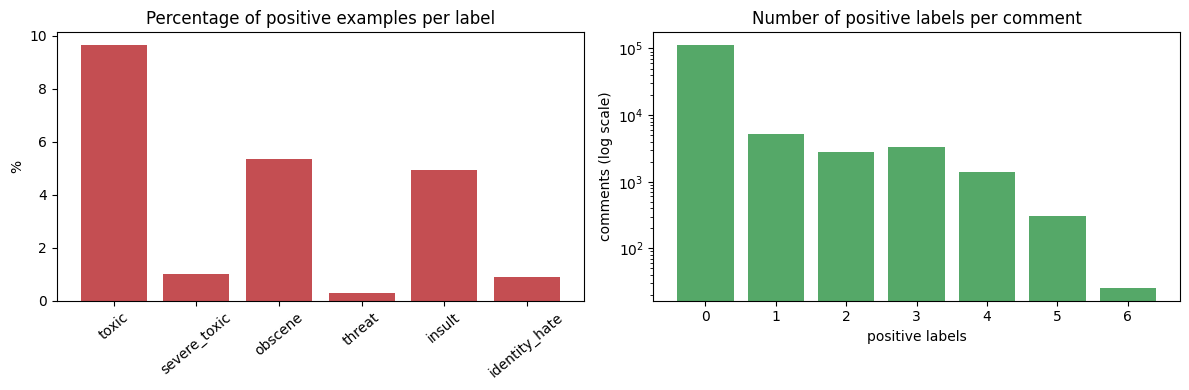

In [7]:
# Label frequency table
label_counts = train[LABELS].sum()
label_table = pd.DataFrame({
    "Positive examples": label_counts,
    "Negative examples": len(train) - label_counts,
    "Positive %": (label_counts / len(train) * 100).round(3),
    "Imbalance ratio (neg:pos)": ((len(train) - label_counts) / label_counts.replace(0, np.nan)).round(1),
})
display(label_table)

n_pos = train[LABELS].sum(axis=1)
labels_per_comment = n_pos.value_counts().sort_index().rename("Comments").to_frame()
labels_per_comment["Percent"] = (labels_per_comment["Comments"] / len(train) * 100).round(2)
labels_per_comment.index.name = "Number of positive labels"
display(labels_per_comment)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(LABELS, label_table["Positive %"], color="#C44E52")
axes[0].set_title("Percentage of positive examples per label"); axes[0].set_ylabel("%")
axes[0].tick_params(axis="x", rotation=40)
axes[1].bar(labels_per_comment.index.astype(str), labels_per_comment["Comments"], color="#55A868")
axes[1].set_title("Number of positive labels per comment"); axes[1].set_yscale("log")
axes[1].set_xlabel("positive labels"); axes[1].set_ylabel("comments (log scale)")
plt.tight_layout(); plt.show()

**Reading the EDA.** Most comments are non-toxic, and some labels (look at `threat`, `identity_hate`, `severe_toxic` in the table above) are far rarer than others. This is **class imbalance**.

Why it matters:
* A model that always says "not toxic" would get a very high *accuracy* and be useless. That is why accuracy is not our metric (see Section 7).
* Rare labels have few training examples, so their AUC is noisier and harder to estimate on a validation set.

**Preprocessing decision:** we do **not** remove punctuation, duplicates, or capital letters by hand. Things like "!!!", ALL CAPS, repeated letters and obfuscated swear words (e.g. `f**k`) are *informative* for toxicity, and character n-grams can use them. We only lowercase text (TF-IDF default) and strip accents.

## 4. Validation Strategy


**Data leakage** = information from the validation/test data leaking into training. A common beginner mistake is fitting the TF-IDF vectorizer on *all* text before splitting: the vocabulary and IDF weights then contain information about validation comments. We avoid this: **every learned preprocessing step is fitted only on the training split**, then applied (`transform`) to validation.

**Stratification:** the split is random with a fixed seed (`42`) and stratified on "comment has at least one toxic label", so both splits contain the same share of toxic comments.

**Limitation:** with rare labels (a few hundred positives), a single random split gives a noisy AUC for those labels, and small differences between models (~0.001) may not be meaningful. Cross-validation would be more stable but costs several times more compute.

In [8]:
y_all = train[LABELS].values.astype(np.int8)
any_toxic = (y_all.sum(axis=1) > 0).astype(int)

idx_tr, idx_val = train_test_split(
    np.arange(len(train)), test_size=0.20, random_state=SEED, stratify=any_toxic
)
X_text_tr,  X_text_val = train[TEXT_COL].values[idx_tr], train[TEXT_COL].values[idx_val]
y_tr, y_val = y_all[idx_tr], y_all[idx_val]
print(f"Train split: {len(idx_tr):,} rows | Validation split: {len(idx_val):,} rows")

split_table = pd.DataFrame({
    "Full train %": (y_all.mean(axis=0) * 100).round(3),
    "Train split %": (y_tr.mean(axis=0) * 100).round(3),
    "Validation split %": (y_val.mean(axis=0) * 100).round(3),
    "Positives in train split": y_tr.sum(axis=0),
    "Positives in validation split": y_val.sum(axis=0),
}, index=LABELS)
display(split_table)

Train split: 102,125 rows | Validation split: 25,532 rows


,Full train %,Train split %,Validation split %,Positives in train split,Positives in validation split
toxic,9.638,9.649,9.596,9854,2450
severe_toxic,0.996,1.017,0.909,1039,232
obscene,5.324,5.303,5.409,5416,1381
threat,0.300,0.296,0.317,302,81
insult,4.928,4.951,4.837,5056,1235
identity_hate,0.904,0.938,0.768,958,196


The percentages should be close across splits. Look at the `Positives in validation split` column: for rare labels this number is small, which is exactly why their AUC is noisy.

## 4. Baseline Model: Word TF-IDF + Logistic Regression

**TF-IDF (`TfidfVectorizer`)** turns each comment into a long vector with one slot per vocabulary item. A slot's value is *term frequency × inverse document frequency*: words that appear often in this comment but rarely across all comments get a high weight, and very common words (like "the") get low weight.

* **Vocabulary / `max_features`:** the set of words (features) kept. We cap it at 50,000 to bound memory and the parameter count.
* **Unigrams and bigrams (`ngram_range=(1, 2)`):** single words *and* two-word phrases ("shut up"), so a bit of word order is captured.
* **`min_df=3`:** ignore terms appearing in fewer than 3 comments (typos seen once add noise and bloat the vocabulary).
* **`sublinear_tf=True`:** use `1 + log(count)` so a word repeated 50 times doesn't dominate.
* **`fit` vs `transform` vs `fit_transform`:** `fit` learns the vocabulary and IDF from the data; `transform` applies what was learned to new text; `fit_transform` does both in one go (use it on training text **only**, then `transform` on validation/test).


**`OneVsRestClassifier`** trains one separate binary logistic regression per label (six here), and `predict_proba` returns a `(n_comments, 6)` matrix of probabilities, one column per label.

In [9]:
# ---- Reusable helper functions (kept small and readable) ----

def make_vectorizers(kind):
    # Build the TF-IDF vectorizer(s). 'word' = baseline; 'word+char' adds character n-grams.
    vecs = [TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=3, max_features=50_000,
                            sublinear_tf=True, strip_accents="unicode", dtype=np.float32)]
    if kind == "word+char":
        # char_wb = character n-grams inside word boundaries; handles misspellings / obfuscation
        vecs.append(TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3, max_features=50_000,
                                    sublinear_tf=True, strip_accents="unicode", dtype=np.float32))
    return vecs

def fit_features(kind, fit_text, other_texts):
    # Fit vectorizers ONLY on fit_text; apply them to every text array in other_texts.
    vecs = make_vectorizers(kind)
    X_fit = sp.hstack([v.fit_transform(fit_text) for v in vecs]).tocsr().astype(np.float32)
    X_others = [sp.hstack([v.transform(t) for v in vecs]).tocsr().astype(np.float32) for t in other_texts]
    return vecs, X_fit, X_others

def make_classifier(C=4.0, class_weight=None):
    return OneVsRestClassifier(
        LogisticRegression(C=C, solver="liblinear", class_weight=class_weight, max_iter=200, random_state=SEED),
        n_jobs=-1)

def per_label_auc(y_true, y_prob):
    return pd.Series({l: roc_auc_score(y_true[:, j], y_prob[:, j]) for j, l in enumerate(LABELS)})

def count_parameters(vecs, clf):
    # Count everything that is 'learned' from data, conservatively.
    n_features = int(sum(len(v.vocabulary_) for v in vecs))
    n_coef  = int(sum(e.coef_.size for e in clf.estimators_))        # one weight per feature per label
    n_inter = int(sum(e.intercept_.size for e in clf.estimators_))   # one bias per label
    n_idf   = int(sum(v.idf_.size for v in vecs))                    # IDF weights are also fitted from data
    return {"n_features": n_features, "n_coef": n_coef, "n_intercepts": n_inter, "n_idf": n_idf,
            "classifier_params": n_coef + n_inter, "total_conservative": n_coef + n_inter + n_idf}

results = {}      # experiment name -> dict of everything we need later
feature_cache = {}  # feature set name -> (vectorizers, X_train, X_val, fit time)

def get_features(kind):
    # Fit features once per feature set on the TRAINING split only, and reuse them across experiments.
    if kind not in feature_cache:
        t0 = time.time()
        vecs, X_tr, (X_val,) = fit_features(kind, X_text_tr, [X_text_val])
        feature_cache[kind] = (vecs, X_tr, X_val, time.time() - t0)
    return feature_cache[kind]

def run_experiment(name, kind, C, class_weight, feature_desc, clf_desc, notes):
    vecs, X_tr, X_val, feat_time = get_features(kind)
    t0 = time.time()
    clf = make_classifier(C, class_weight).fit(X_tr, y_tr)
    fit_time = time.time() - t0
    prob = clf.predict_proba(X_val)
    aucs = per_label_auc(y_val, prob)
    params = count_parameters(vecs, clf)
    assert params["total_conservative"] < PARAM_LIMIT, "Parameter limit violated!"
    results[name] = dict(kind=kind, C=C, class_weight=class_weight, feature_desc=feature_desc,
                         clf_desc=clf_desc, aucs=aucs, mean_auc=aucs.mean(), params=params,
                         time=feat_time + fit_time, notes=notes)
    print(f"{name}: mean val AUC = {aucs.mean():.5f} | total params = {params['total_conservative']:,} | time = {feat_time + fit_time:.0f}s")

In [10]:
# ---- Baseline: word TF-IDF + logistic regression ----
run_experiment("Baseline", "word", C=4.0, class_weight=None,
               feature_desc="Word TF-IDF (1-2 grams, 50k max)", clf_desc="Logistic Regression (C=4)",
               notes="Reference model")
vecs_b, Xtr_b, Xval_b, _ = feature_cache["word"]
print("Training matrix shape (rows x features):", Xtr_b.shape, "| sparse dtype:", Xtr_b.dtype)
display(results["Baseline"]["aucs"].round(5).rename("Validation ROC AUC").to_frame().T)
print(f"Baseline mean validation ROC AUC: {results['Baseline']['mean_auc']:.5f}")

Baseline: mean val AUC = 0.97900 | total params = 350,006 | time = 26s
Training matrix shape (rows x features): (102125, 50000) | sparse dtype: float32


,toxic,severe_toxic,obscene,threat,insult,identity_hate
Validation ROC AUC,0.97034,0.98173,0.98028,0.99059,0.97364,0.97742


Baseline mean validation ROC AUC: 0.97900


The row above shows the AUC of each label and the mean (the competition metric). Rare labels usually score less reliably than common ones because there are fewer positive examples to learn from and to measure on.

## 5. Model Comparison and Improvements

We now test a small, justified set of changes. Everything uses the **same validation split** and the same seed:

| # | Experiment | Why test it |
|---|---|---|
| 2 | Word + **character** TF-IDF | Toxic text is full of misspellings and obfuscation (`idi0t`, `f*ck`). Character n-grams (2–5 letters inside words) can still match these patterns, which word features treat as unknown words. |
| 3 | Word + char with `class_weight="balanced"` | Tests whether re-weighting rare positives helps (see Section 7). |
| 4a / 4b | Word + char with `C = 1` and `C = 10` | Tests regularisation strength: weaker or stronger penalty than the default `C = 4`. |

`C` was chosen for experiments 4a/4b from a tiny grid, and the winner is picked using the validation score; a slight optimistic bias is therefore possible, which we mention in the conclusion. Optional alternatives (Linear SVM, Naive Bayes, SGD) are skipped deliberately: they would add complexity but are unlikely to beat well-regularised logistic regression on the same features for a beginner-friendly submission.

In [11]:
run_experiment("Experiment 2", "word+char", C=4.0, class_weight=None,
               feature_desc="Word + char TF-IDF (50k + 50k)", clf_desc="Logistic Regression (C=4)",
               notes="Test added character features")
run_experiment("Experiment 3", "word+char", C=4.0, class_weight="balanced",
               feature_desc="Word + char TF-IDF (50k + 50k)", clf_desc="Logistic Regression (C=4, balanced weights)",
               notes="Test class weighting")
run_experiment("Experiment 4a", "word+char", C=1.0, class_weight=None,
               feature_desc="Word + char TF-IDF (50k + 50k)", clf_desc="Logistic Regression (C=1)",
               notes="Stronger regularisation")
run_experiment("Experiment 4b", "word+char", C=10.0, class_weight=None,
               feature_desc="Word + char TF-IDF (50k + 50k)", clf_desc="Logistic Regression (C=10)",
               notes="Weaker regularisation")

Experiment 2: mean val AUC = 0.98429 | total params = 700,006 | time = 138s
Experiment 3: mean val AUC = 0.98405 | total params = 700,006 | time = 160s
Experiment 4a: mean val AUC = 0.98549 | total params = 700,006 | time = 131s
Experiment 4b: mean val AUC = 0.98182 | total params = 700,006 | time = 153s


,Experiment,Text features,Classifier,Mean validation ROC AUC,Parameter count,Training time (s),Notes
0,Baseline,"Word TF-IDF (1-2 grams, 50k max)",Logistic Regression (C=4),0.97900,350006,25.6,Reference model
1,Experiment 2,Word + char TF-IDF (50k + 50k),Logistic Regression (C=4),0.98429,700006,137.6,Test added character features
2,Experiment 3,Word + char TF-IDF (50k + 50k),"Logistic Regression (C=4, balanced weights)",0.98405,700006,160.0,Test class weighting
3,Experiment 4a,Word + char TF-IDF (50k + 50k),Logistic Regression (C=1),0.98549,700006,130.7,Stronger regularisation
4,Experiment 4b,Word + char TF-IDF (50k + 50k),Logistic Regression (C=10),0.98182,700006,153.0,Weaker regularisation


**Per-label validation ROC AUC**

,toxic,severe_toxic,obscene,threat,insult,identity_hate,MEAN
Baseline,0.97034,0.98173,0.98028,0.99059,0.97364,0.97742,0.97900
Experiment 2,0.97765,0.98342,0.98921,0.99119,0.97841,0.98583,0.98429
Experiment 3,0.97744,0.98282,0.98982,0.99121,0.97928,0.98375,0.98405
Experiment 4a,0.97855,0.98560,0.98959,0.99093,0.98107,0.98721,0.98549
Experiment 4b,0.97532,0.97994,0.98729,0.99075,0.97434,0.98328,0.98182


**Absolute AUC difference vs Baseline (positive = better than baseline)**

,toxic,severe_toxic,obscene,threat,insult,identity_hate,MEAN
Baseline,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000
Experiment 2,0.00731,0.00170,0.00893,0.00060,0.00477,0.00841,0.00529
Experiment 3,0.00710,0.00109,0.00954,0.00062,0.00563,0.00633,0.00505
Experiment 4a,0.00821,0.00388,0.00931,0.00034,0.00742,0.00979,0.00649
Experiment 4b,0.00498,-0.00179,0.00701,0.00017,0.00070,0.00586,0.00282



Best experiment by mean validation ROC AUC: Experiment 4a (0.98549; baseline 0.97900; difference +0.00649)


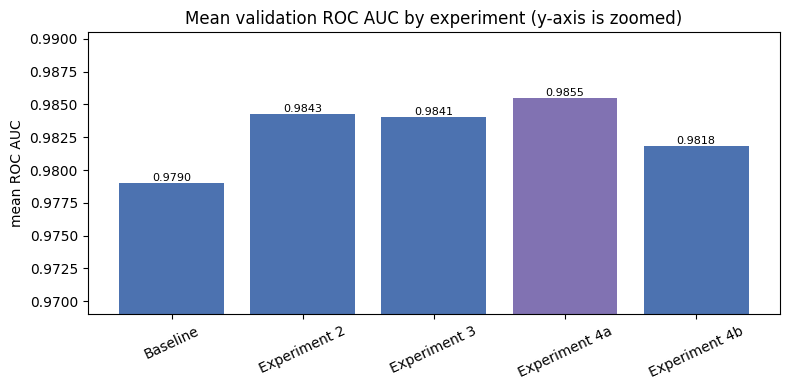

In [12]:
# ---- Programmatically generated comparison tables (no hand-typed scores) ----
summary = pd.DataFrame([{
    "Experiment": n, "Text features": r["feature_desc"], "Classifier": r["clf_desc"],
    "Mean validation ROC AUC": round(r["mean_auc"], 5),
    "Parameter count": r["params"]["total_conservative"],
    "Training time (s)": round(r["time"], 1), "Notes": r["notes"],
} for n, r in results.items()])
display(summary)

label_auc_table = pd.DataFrame({n: r["aucs"] for n, r in results.items()}).T
label_auc_table["MEAN"] = label_auc_table[LABELS].mean(axis=1)
display(Markdown("**Per-label validation ROC AUC**"))
display(label_auc_table.round(5))

diff_table = label_auc_table.subtract(label_auc_table.loc["Baseline"], axis=1)
display(Markdown("**Absolute AUC difference vs Baseline (positive = better than baseline)**"))
display(diff_table.round(5))

best_name = label_auc_table["MEAN"].idxmax()
print(f"\nBest experiment by mean validation ROC AUC: {best_name} "
      f"({label_auc_table.loc[best_name, 'MEAN']:.5f}; baseline {label_auc_table.loc['Baseline', 'MEAN']:.5f}; "
      f"difference {label_auc_table.loc[best_name, 'MEAN'] - label_auc_table.loc['Baseline', 'MEAN']:+.5f})")

fig, ax = plt.subplots(figsize=(8, 4))
means = label_auc_table["MEAN"]
bars = ax.bar(means.index, means.values, color=["#8172B2" if n == best_name else "#4C72B0" for n in means.index])
ax.set_ylim(max(0.5, means.min() - 0.01), min(1.0, means.max() + 0.005))   # zoomed axis: differences are small
ax.set_title("Mean validation ROC AUC by experiment (y-axis is zoomed)"); ax.set_ylabel("mean ROC AUC")
for b, v in zip(bars, means.values): ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.4f}", ha="center", va="bottom", fontsize=8)
plt.xticks(rotation=25); plt.tight_layout(); plt.show()

In [13]:

base = results["Baseline"]["mean_auc"]
lines = []
for n, r in results.items():
    if n == "Baseline": continue
    d = r["mean_auc"] - base
    verdict = "improved on" if d > 0 else ("matched" if d == 0 else "did NOT improve on")
    lines.append(f"- **{n}** ({r['notes']}) {verdict} the baseline by **{d:+.5f}** mean AUC.")
display(Markdown("\n".join(lines)))
d2 = results["Experiment 2"]["mean_auc"] - base
display(Markdown(
    f"**Character features:** the change in mean AUC is {d2:+.5f}. " +
    ("A gain is plausible because character n-grams can match misspelled or obfuscated insults that word features miss. "
     if d2 > 0 else "No gain here suggests the word n-grams already capture most of the signal in this data. ") +
    "Differences of this size on a single split, especially for rare labels, should be read with caution."))

- **Experiment 2** (Test added character features) improved on the baseline by **+0.00529** mean AUC.
- **Experiment 3** (Test class weighting) improved on the baseline by **+0.00505** mean AUC.
- **Experiment 4a** (Stronger regularisation) improved on the baseline by **+0.00649** mean AUC.
- **Experiment 4b** (Weaker regularisation) improved on the baseline by **+0.00282** mean AUC.

**Character features:** the change in mean AUC is +0.00529. A gain is plausible because character n-grams can match misspelled or obfuscated insults that word features miss. Differences of this size on a single split, especially for rare labels, should be read with caution.

## 6. Class Imbalance



In [14]:
cw = results["Experiment 3"]["mean_auc"] - results["Experiment 2"]["mean_auc"]
cw_tbl = pd.DataFrame({"Unweighted (Exp 2)": results["Experiment 2"]["aucs"],
                       "Balanced weights (Exp 3)": results["Experiment 3"]["aucs"]})
cw_tbl["Difference"] = cw_tbl.iloc[:, 1] - cw_tbl.iloc[:, 0]
display(cw_tbl.round(5))
print(f"Mean AUC difference from class weighting: {cw:+.5f} ->",
      "class weighting is justified by validation" if cw > 0 else "class weighting is NOT justified; not retained")

,Unweighted (Exp 2),Balanced weights (Exp 3),Difference
toxic,0.97765,0.97744,-0.00021
severe_toxic,0.98342,0.98282,-0.00060
obscene,0.98921,0.98982,0.00060
threat,0.99119,0.99121,0.00003
insult,0.97841,0.97928,0.00086
identity_hate,0.98583,0.98375,-0.00208


Mean AUC difference from class weighting: -0.00023 -> class weighting is NOT justified; not retained


## 7. Parameter-Count Verification


In [15]:
param_table = pd.DataFrame([{
    "Experiment": n,
    "Text features": r["params"]["n_features"],
    "Classifier coefficients (6 x F)": r["params"]["n_coef"],
    "Intercepts": r["params"]["n_intercepts"],
    "Classifier parameters": r["params"]["classifier_params"],
    "IDF weights (counted conservatively)": r["params"]["n_idf"],
    "Total learned parameters": r["params"]["total_conservative"],
    "< 1,000,000 ?": r["params"]["total_conservative"] < PARAM_LIMIT,
} for n, r in results.items()])
display(param_table)

for n, r in results.items():
    p = r["params"]
    assert p["n_coef"] == 6 * p["n_features"], "coef count should be 6 x features"
    assert p["n_intercepts"] == 6
    assert p["total_conservative"] < PARAM_LIMIT, f"{n} exceeds the parameter limit"
print("ASSERTION PASSED: every experiment has fewer than 1,000,000 learned parameters.")
print("Formula check: 6 x 100,000 + 6 =", 6 * 100_000 + 6)

,Experiment,Text features,Classifier coefficients (6 x F),Intercepts,Classifier parameters,IDF weights (counted conservatively),Total learned parameters,"< 1,000,000 ?"
0,Baseline,50000,300000,6,300006,50000,350006,True
1,Experiment 2,100000,600000,6,600006,100000,700006,True
2,Experiment 3,100000,600000,6,600006,100000,700006,True
3,Experiment 4a,100000,600000,6,600006,100000,700006,True
4,Experiment 4b,100000,600000,6,600006,100000,700006,True


ASSERTION PASSED: every experiment has fewer than 1,000,000 learned parameters.
Formula check: 6 x 100,000 + 6 = 600006


## 8. Final Model Selection

We choose the **compliant model with the best mean validation ROC AUC**. If two models are practically tied, simplicity and speed should break the tie (we don't pick a model just because it is more complicated).

In [16]:
sel = pd.DataFrame({
    "Mean validation ROC AUC": {n: r["mean_auc"] for n, r in results.items()},
    "Complexity (features)": {n: r["params"]["n_features"] for n, r in results.items()},
    "Total parameters": {n: r["params"]["total_conservative"] for n, r in results.items()},
    "Runtime (s)": {n: round(r["time"], 1) for n, r in results.items()},
    "Interpretability": {n: "High (linear weights per n-gram)" for n in results},
    "Compliant (<1M params, train data only)": {n: r["params"]["total_conservative"] < PARAM_LIMIT for n, r in results.items()},
})
sel = sel.sort_values("Mean validation ROC AUC", ascending=False)
display(sel.round(5))

compliant = sel[sel["Compliant (<1M params, train data only)"]]
FINAL_NAME = compliant["Mean validation ROC AUC"].idxmax()
FINAL = results[FINAL_NAME]

# Tie-break: if a simpler (fewer features) model is within 0.0005 AUC of the best, prefer it.
close = compliant[compliant["Mean validation ROC AUC"] >= compliant["Mean validation ROC AUC"].max() - 0.0005]
if len(close) > 1:
    simpler = close.sort_values(["Complexity (features)", "Runtime (s)"]).index[0]
    if simpler != FINAL_NAME:
        print(f"Note: {simpler} is within 0.0005 AUC of {FINAL_NAME} and simpler/faster; "
              f"keeping the validation winner {FINAL_NAME} (we pick strictly by validation score).")
print(f"\nSELECTED MODEL: {FINAL_NAME} -> {FINAL['feature_desc']} + {FINAL['clf_desc']}")
print(f"Validation mean ROC AUC = {FINAL['mean_auc']:.5f}")

,Mean validation ROC AUC,Complexity (features),Total parameters,Runtime (s),Interpretability,"Compliant (<1M params, train data only)"
Experiment 4a,0.98549,100000,700006,130.7,High (linear weights per n-gram),True
Experiment 2,0.98429,100000,700006,137.6,High (linear weights per n-gram),True
Experiment 3,0.98405,100000,700006,160.0,High (linear weights per n-gram),True
Experiment 4b,0.98182,100000,700006,153.0,High (linear weights per n-gram),True
Baseline,0.97900,50000,350006,25.6,High (linear weights per n-gram),True



SELECTED MODEL: Experiment 4a -> Word + char TF-IDF (50k + 50k) + Logistic Regression (C=1)
Validation mean ROC AUC = 0.98549


## 9. Final Training and Predictions

Now that the configuration is fixed, we **refit on all labelled training data** (train + validation = more data, usually slightly better). The vectorizer is fitted on all training comments only; the competition **test comments are only transformed**, never used for fitting.

In [17]:
t0 = time.time()
full_text = train[TEXT_COL].values
vecs_final, X_full, (X_test,) = fit_features(FINAL["kind"], full_text, [test[TEXT_COL].values])
clf_final = make_classifier(FINAL["C"], FINAL["class_weight"]).fit(X_full, y_all)
test_prob = clf_final.predict_proba(X_test)          # shape (n_test, 6), columns follow LABELS order
print(f"Final fit + predict time: {time.time() - t0:.0f}s | X_full {X_full.shape} | X_test {X_test.shape}")

assert test_prob.shape == (len(test), 6)
assert np.isfinite(test_prob).all() and test_prob.min() >= 0 and test_prob.max() <= 1

final_params = count_parameters(vecs_final, clf_final)
assert final_params["total_conservative"] < PARAM_LIMIT
print("Final model parameter count:", final_params)

# Build the submission using the exact column order of sample_submission.csv; keep test ID order unchanged.
submission = pd.DataFrame(test_prob, columns=LABELS)
submission.insert(0, ID_COL, test[ID_COL].values)
submission = submission[SUB_COLUMNS]
os.makedirs(OUT_DIR, exist_ok=True)   # OUT_DIR = /kaggle/working (defined in the Section 2 setup cell)
SUB_FILE = os.path.join(OUT_DIR, "submission.csv")
submission.to_csv(SUB_FILE, index=False)
print("Saved:", SUB_FILE)

Final fit + predict time: 160s | X_full (127657, 100000) | X_test (31914, 100000)
Final model parameter count: {'n_features': 100000, 'n_coef': 600000, 'n_intercepts': 6, 'n_idf': 100000, 'classifier_params': 600006, 'total_conservative': 700006}
Saved: /kaggle/working/submission.csv


## 10. Submission Validation

We reload the saved CSV from disk and check it against the competition format.

In [18]:
check = pd.read_csv(SUB_FILE)
probs = check[LABELS].values.astype(float)
checks = {
    "Columns exactly match sample_submission (names and order)": list(check.columns) == SUB_COLUMNS,
    "Row count equals test rows": len(check) == len(test),
    "IDs match test IDs in the same order": check[ID_COL].astype(str).tolist() == test[ID_COL].astype(str).tolist(),
    "IDs match sample_submission ID set": set(check[ID_COL]) == set(sample_sub[ID_COL]),
    "No duplicate IDs": check[ID_COL].is_unique,
    "No missing values": not check.isna().any().any(),
    "No infinite values": bool(np.isfinite(probs).all()),
    "All probabilities within [0, 1]": bool(probs.min() >= 0 and probs.max() <= 1),
    "No unwanted index column": not any(str(c).startswith("Unnamed") for c in check.columns),
    "Continuous probabilities, not binary 0/1": bool((check[LABELS].nunique() > 2).all()),
    "File saved at /kaggle/working/submission.csv": os.path.abspath(SUB_FILE) == "/kaggle/working/submission.csv" and os.path.isfile(SUB_FILE),
}
val_summary = pd.DataFrame({"Check": list(checks), "Passed": list(checks.values())})
display(val_summary)
assert all(checks.values()), "Submission validation failed!"
print("ALL SUBMISSION CHECKS PASSED\n")
print("Output file path:", os.path.abspath(SUB_FILE))
print("Submission shape  :", check.shape)
display(check.head(5))
display(check[LABELS].describe().T[["min", "mean", "max"]].round(5))

,Check,Passed
0,Columns exactly match sample_submission (names and order),True
1,Row count equals test rows,True
2,IDs match test IDs in the same order,True
3,IDs match sample_submission ID set,True
4,No duplicate IDs,True
5,No missing values,True
6,No infinite values,True
7,"All probabilities within [0, 1]",True
8,No unwanted index column,True
9,"Continuous probabilities, not binary 0/1",True


ALL SUBMISSION CHECKS PASSED

Output file path: /kaggle/working/submission.csv
Submission shape  : (31914, 7)


,id,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,dsai127657,0.015268,0.001714,0.007815,0.001357,0.008432,0.003037
1,dsai127658,0.239910,0.001904,0.023974,0.000506,0.046786,0.002565
2,dsai127659,0.004068,0.000832,0.003998,0.000491,0.002402,0.001231
3,dsai127660,0.084351,0.005250,0.052964,0.003453,0.054106,0.008478
4,dsai127661,0.002716,0.000422,0.002157,0.000439,0.001563,0.000858


,min,mean,max
toxic,0.00007,0.09384,1.00000
severe_toxic,0.00008,0.01018,0.97842
obscene,0.00029,0.05172,1.00000
threat,0.00006,0.00295,0.97717
insult,0.00011,0.04802,0.99999
identity_hate,0.00009,0.00859,0.99134


## 11. Results and Conclusion

Everything in the next cell is generated from the actual experiment results.

In [19]:
base_auc = results["Baseline"]["mean_auc"]
best_auc = FINAL["mean_auc"]
conclusion = pd.DataFrame({
    "Value": {
        "Baseline mean validation ROC AUC": round(base_auc, 5),
        "Best mean validation ROC AUC": round(best_auc, 5),
        "Improvement over baseline (absolute)": round(best_auc - base_auc, 5),
        "Selected model": f"{FINAL_NAME}: {FINAL['feature_desc']} + {FINAL['clf_desc']}",
        "Final model features": final_params["n_features"],
        "Final model total learned parameters": final_params["total_conservative"],
        "Classifier-only parameters (coef + intercepts)": final_params["classifier_params"],
    }
})
display(conclusion)
display(Markdown("**Per-label validation ROC AUC of the selected model**"))
display(FINAL["aucs"].round(5).rename("ROC AUC").to_frame().T)

display(Markdown(f'''
**What worked / what did not.**
- Selected: **{FINAL_NAME}**, which changed mean validation AUC by **{best_auc - base_auc:+.5f}** versus the word-only baseline.
- Character features (Exp 2) changed the mean AUC by {results['Experiment 2']['mean_auc'] - base_auc:+.5f}.
- Class weighting (Exp 3) changed it by {results['Experiment 3']['mean_auc'] - results['Experiment 2']['mean_auc']:+.5f} relative to the unweighted model with the same features.
- Regularisation: C=1 -> {results['Experiment 4a']['mean_auc']:.5f}, C=4 -> {results['Experiment 2']['mean_auc']:.5f}, C=10 -> {results['Experiment 4b']['mean_auc']:.5f}.

**Limitations.** (1) These are *validation* scores from one random split; the competition's test score is unknown and **no test ROC AUC is claimed**. (2) Rare labels have few validation positives, so their AUCs are noisy. (3) Choosing `C`/features on the same validation split gives a small optimistic bias. (4) Linear models cannot capture sarcasm or deep context.


'''))

,Value
Baseline mean validation ROC AUC,0.979
Best mean validation ROC AUC,0.98549
Improvement over baseline (absolute),0.00649
Selected model,Experiment 4a: Word + char TF-IDF (50k + 50k) + Logistic Regression (C=1)
Final model features,100000
Final model total learned parameters,700006
Classifier-only parameters (coef + intercepts),600006


**Per-label validation ROC AUC of the selected model**

,toxic,severe_toxic,obscene,threat,insult,identity_hate
ROC AUC,0.97855,0.9856,0.98959,0.99093,0.98107,0.98721



**What worked / what did not.**
- Selected: **Experiment 4a**, which changed mean validation AUC by **+0.00649** versus the word-only baseline.
- Character features (Exp 2) changed the mean AUC by +0.00529.
- Class weighting (Exp 3) changed it by -0.00023 relative to the unweighted model with the same features.
- Regularisation: C=1 -> 0.98549, C=4 -> 0.98429, C=10 -> 0.98182.

**Limitations.** (1) These are *validation* scores from one random split; the competition's test score is unknown and **no test ROC AUC is claimed**. (2) Rare labels have few validation positives, so their AUCs are noisy. (3) Choosing `C`/features on the same validation split gives a small optimistic bias. (4) Linear models cannot capture sarcasm or deep context.


